<a href="https://colab.research.google.com/github/cosminpelin21/pytorch-mlp-fashion-mnist/blob/main/fashion_mnist_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fashion-MNIST Image Classification using PyTorch

End-to-end Deep Learning pipeline built with PyTorch to train, validate, and evaluate a Multi-Layer Perceptron (MLP) on the Fashion-MNIST dataset.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
from typing import List, Tuple, Any

In [2]:
class FashionMNISTDataset(Dataset):
    def __init__(self, csv_file: str):
        self.data = pd.read_csv(csv_file)

    def __len__(self) -> int:
        return len(self.data)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int]:
        row = self.data.iloc[idx]
        label = int(row.iloc[0])
        pixels = row.iloc[1:].values.astype('float32')
        pixels = (pixels / 255.0)
        pixels = (pixels - 0.5) / 0.5
        img_tensor = torch.tensor(pixels, dtype=torch.float32)

        return img_tensor, label

In [3]:
class MLP(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_classes: int):
        super(MLP, self).__init__()
        self.layer_stack = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.layer_stack(x)
        return logits

In [4]:
def train_epoch(dataloader: DataLoader, model: nn.Module, loss_fn: nn.Module, optimizer: torch.optim.Optimizer) -> float:
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for X, y in dataloader:
        pred = model(X)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (pred.argmax(1) == y).type(torch.float).sum().item()
        total += y.size(0)

    return correct / total

In [5]:
def evaluate(dataloader: DataLoader, model: nn.Module) -> Tuple[float, List[int], List[int]]:
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
            total += y.size(0)
            all_preds.extend(pred.argmax(1).cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    return correct / total, all_labels, all_preds

In [7]:
BATCH_SIZE = 64
LR = 0.001
EPOCHS = 10

train_dataset = FashionMNISTDataset(csv_file='./data/fashion-mnist_train.csv')
test_dataset = FashionMNISTDataset(csv_file='./data/fashion-mnist_test.csv')

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

model = MLP(input_size=784, hidden_size=512, num_classes=10)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LR)

train_acc_history = []
test_acc_history = []

for t in range(EPOCHS):
    print(f"Epoca {t+1}...")
    train_acc = train_epoch(train_loader, model, loss_fn, optimizer)
    test_acc, _, _ = evaluate(test_loader, model)

    train_acc_history.append(train_acc)
    test_acc_history.append(test_acc)
    print(f"--> Train Acc: {train_acc:.4f}, Test Acc: {test_acc:.4f}")

Epoca 1...
--> Train Acc: 0.4254, Test Acc: 0.5594
Epoca 2...
--> Train Acc: 0.6210, Test Acc: 0.6834
Epoca 3...
--> Train Acc: 0.7054, Test Acc: 0.7203
Epoca 4...
--> Train Acc: 0.7320, Test Acc: 0.7345
Epoca 5...
--> Train Acc: 0.7450, Test Acc: 0.7505
Epoca 6...
--> Train Acc: 0.7555, Test Acc: 0.7588
Epoca 7...
--> Train Acc: 0.7645, Test Acc: 0.7706
Epoca 8...
--> Train Acc: 0.7732, Test Acc: 0.7760
Epoca 9...
--> Train Acc: 0.7801, Test Acc: 0.7880
Epoca 10...
--> Train Acc: 0.7875, Test Acc: 0.7918


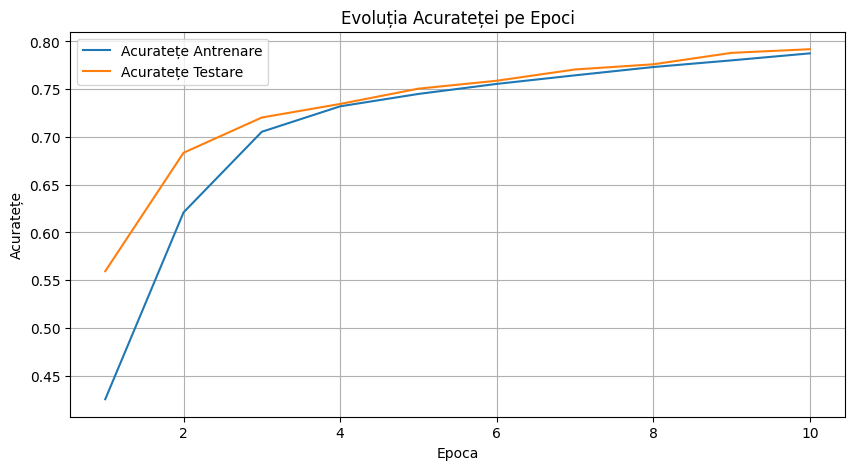

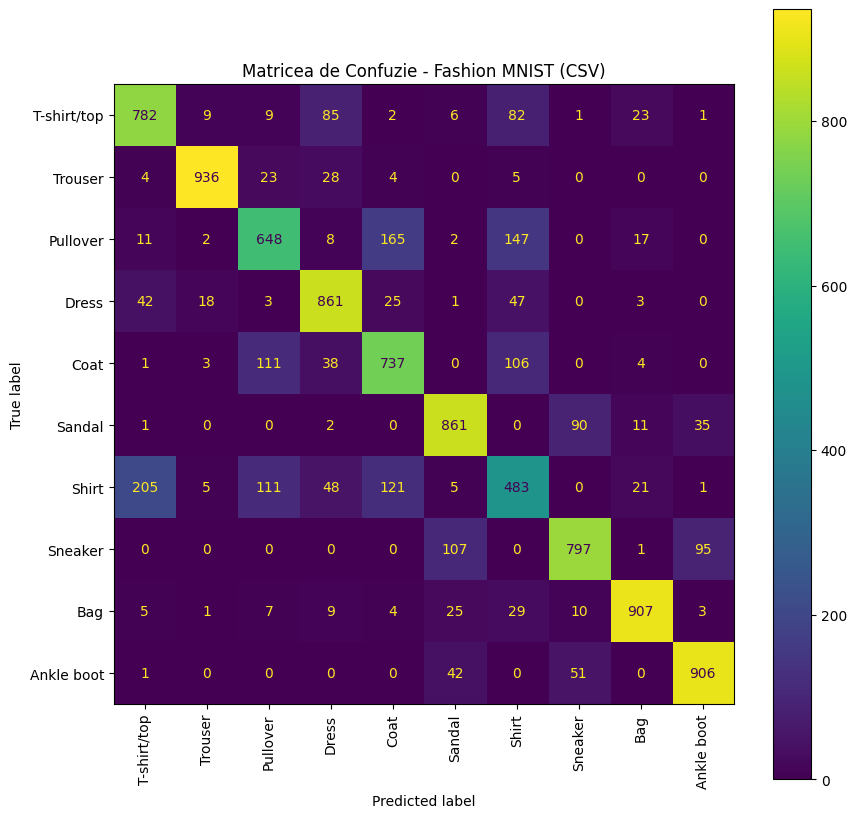

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(range(1, EPOCHS + 1), train_acc_history, label='Acuratețe Antrenare')
plt.plot(range(1, EPOCHS + 1), test_acc_history, label='Acuratețe Testare')

plt.xlabel('Epoca')
plt.ylabel('Acuratețe')
plt.title('Evoluția Acurateței pe Epoci')
plt.legend()
plt.grid(True)
plt.show()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

final_acc, true_labels, pred_labels = evaluate(test_loader, model)

cm = confusion_matrix(true_labels, pred_labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap='viridis', xticks_rotation='vertical')
plt.title("Matricea de Confuzie - Fashion MNIST (CSV)")
plt.show()